# Differentiated Bertrand with editable user inputs

Firms sell differentiated products, so both may attract customers at different prices. Each consumer group has a population $N_g$, price sensitivity $\alpha_g>0$, product utilities $v_{ig}$, and outside-option utility $v_{0g}$:

$$s_{ig}=\frac{\exp(v_{ig}-\alpha_gp_i)}{\exp(v_{0g})+\sum_j\exp(v_{jg}-\alpha_gp_j)},\qquad Q_i=\sum_gN_gs_{ig},\qquad \pi_i=(p_i-c_i)Q_i.$$

The outside option means no purchase. Utilities are dimensionless and price sensitivities are per price unit. Shifting all utilities, including the outside option, by a common constant does not change demand.

Edit the **Pydantic input cell** below, or load a user-authored JSON value through the same input class. The supplied numbers are illustrative, not calibrated estimates. Both LLM firms act from permitted information; the numerical solver runs separately. The shared runtime, LLM policy, costs, profits, pricing action, event log, and job cleanup are reused.

**Live mode is enabled.** Re-execution makes bounded calls using `.env` (`API_KEY`, `MODEL`). Switch to fake mode for offline checks. The numerical benchmark checks unilateral improvements with two methods, but it is not a proof of uniqueness or globally optimal best responses.


In [1]:
from pathlib import Path
from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import numpy as np

from examples.differentiated_bertrand import (
    ConsumerSegment, FirmInput, DifferentiatedBertrandInputs, run_job, run_live_job,
)
from components.mechanisms.bertrand import PriceDomain
from components.common.economics.segmented_logit import SegmentedLogitDemand
from simulation_core.logging import replay, stream_action_trace


## User inputs

Replace the firms and segments below with your inputs, then set `INPUT_SOURCE = "user"`. Required numeric inputs are validated; the compiler does not invent missing costs, populations, sensitivities, or product utilities. Outside utility defaults to zero and is reported as an assumption when omitted.

Price bounds can differ by firm. Information permissions default to public demand parameters, costs, bounds, and committed history, plus each firm's own private facts/memory. Pass a complete per-firm `permissions` mapping to override this default. A hidden field is never supplied just because a policy might find it useful.


In [2]:
INPUT_SOURCE = "illustrative"  # Change to "user" after replacing these example values.
INPUTS = DifferentiatedBertrandInputs(
    firms=(
        FirmInput(id="A", marginal_cost=1.0, price_domain=PriceDomain(lower=0.0, upper=10.0)),
        FirmInput(id="B", marginal_cost=1.2, price_domain=PriceDomain(lower=0.0, upper=10.0)),
    ),
    segments=(
        ConsumerSegment(id="students", population=400.0, price_sensitivity=1.5,
                        utilities={"A": 3.5, "B": 3.0}),
        ConsumerSegment(id="professionals", population=350.0, price_sensitivity=0.8,
                        utilities={"A": 4.0, "B": 4.2}),
        ConsumerSegment(id="budget", population=250.0, price_sensitivity=2.0,
                        utilities={"A": 2.5, "B": 2.8}),
    ),
)
# Alternatively: INPUTS = DifferentiatedBertrandInputs.model_validate_json(Path("your_inputs.json").read_text())
assert DifferentiatedBertrandInputs.model_validate_json(INPUTS.model_dump_json()) == INPUTS
print("Input source:", INPUT_SOURCE)
print("Firms:", [(f.id, f.marginal_cost, f.price_domain.model_dump()) for f in INPUTS.firms])
rows = ["| Segment | Population | Price sensitivity | Product utilities | Outside utility |",
        "|---|---:|---:|---|---:|"]
for segment in INPUTS.segments:
    rows.append(f"| {segment.id} | {segment.population:g} | {segment.price_sensitivity:g} | {segment.utilities} | {segment.outside_utility:g} |")
display(Markdown("\n".join(rows)))


Input source: illustrative
Firms: [('A', 1.0, {'lower': 0.0, 'upper': 10.0}), ('B', 1.2, {'lower': 0.0, 'upper': 10.0})]


| Segment | Population | Price sensitivity | Product utilities | Outside utility |
|---|---:|---:|---|---:|
| students | 400 | 1.5 | {'A': 3.5, 'B': 3.0} | 0 |
| professionals | 350 | 0.8 | {'A': 4.0, 'B': 4.2} | 0 |
| budget | 250 | 2 | {'A': 2.5, 'B': 2.8} | 0 |

## Primary LLM simulation

No benchmark answer is included in an actor's observation. Current rival prices remain hidden until all actions commit. Each action requires a concise stated rationale; these explanations are not private internal reasoning. The notebook records one simultaneous round by default.


In [3]:
USE_LIVE_API = True
with stream_action_trace():
    artifact = (run_live_job(INPUTS, input_source=INPUT_SOURCE) if USE_LIVE_API
                else run_job(INPUTS, input_source=INPUT_SOURCE))
config, result, report = artifact.manifest.simulation, artifact.result, artifact.benchmark
assert report is not None
actor_ids = tuple(firm.id for firm in INPUTS.firms)
observed = result.outcomes[-1]
prices = {a.actor_id: a.payload["price"] for a in result.events[-1].actions}
print("Mode:", "LIVE MODEL" if USE_LIVE_API else "FAKE GATEWAY — configured fixture prices")
print("Primary run:", result.status)
print("Benchmark:", report.result.status, "| certification:", report.result.certification)
print("Consumer demand:", observed.metrics["total_quantity"])
print("Outside-option demand:", observed.metrics["outside_quantity"])
print("Declared population:", observed.metrics["total_population"])


{"tick": 1, "actor_id": "A", "action": {"actor_id": "A", "kind": "set_price", "payload": {"price": 2.3}}, "rationale": "No history; assumed rival B near cost-plus ~2.5. Computed logit quantities across 3 segments for A prices 2.0-3.0; profit peaks near 2.3 with margin 1.3. Chose 2.3 within [0,10]."}


{"tick": 1, "actor_id": "B", "action": {"actor_id": "B", "kind": "set_price", "payload": {"price": 2.5}}, "rationale": "No history, so assume rival A prices near cost-plus ~2.5. At that rival price, B demand from professionals (high utility 4.2, low sensitivity 0.8) plus students/budget gives highest profit near 2.5 (margin 1.3 x ~289 units) vs lower price loses margin and higher price loses volume. Chose 2.5 within [0,10] to maximize own profit."}


Mode: LIVE MODEL
Primary run: completed
Benchmark: solved | certification: numerical
Consumer demand: 620.0633852655521
Outside-option demand: 379.93661473444786
Declared population: 1000.0


## Prices, quantities, profits, and deviations

All numerical candidates found are retained below. Price/profit deltas are **LLM outcome minus candidate equilibrium**. Estimated unilateral gains measure how much more a firm could earn by changing its own price while keeping rival prices fixed. Small verified gains support an approximate bounded-game equilibrium; they are not a proof that the search found every equilibrium.

If the benchmark fails or exhausts its budget, the primary LLM result remains available. The notebook displays that status without substituting solver choices for actor choices.


In [4]:
if report.result.equilibria:
    rows = ["| Candidate | Firm | LLM price | Benchmark price | Price delta | LLM quantity | Benchmark quantity | LLM profit | Benchmark profit | Estimated LLM deviation gain |",
            "|---:|---|---:|---:|---:|---:|---:|---:|---:|---:|"]
    for comparison in report.comparisons:
        equilibrium = report.result.equilibria[comparison.equilibrium_index]
        reference_prices = {a.actor_id:a.payload["price"] for a in equilibrium.actions}
        for aid in actor_ids:
            rows.append(f"| {comparison.equilibrium_index} | {aid} | {prices[aid]:.5f} | {reference_prices[aid]:.5f} | "
                        f"{comparison.numeric_action_deltas[aid]['price']:+.5f} | {observed.metrics['quantities'][aid]:.3f} | "
                        f"{equilibrium.outcome.metrics['quantities'][aid]:.3f} | {observed.payoffs[aid]:.3f} | "
                        f"{equilibrium.outcome.payoffs[aid]:.3f} | {report.observed_regrets[aid]:.6g} |")
    display(Markdown("\n".join(rows)))
else:
    print("No verified candidate available; inspect benchmark diagnostics below.")
    print("LLM prices:", prices)
    print("LLM quantities:", observed.metrics["quantities"])
    print("LLM profits:", observed.payoffs)


| Candidate | Firm | LLM price | Benchmark price | Price delta | LLM quantity | Benchmark quantity | LLM profit | Benchmark profit | Estimated LLM deviation gain |
|---:|---|---:|---:|---:|---:|---:|---:|---:|---:|
| 0 | A | 2.30000 | 2.34906 | -0.04906 | 353.779 | 344.375 | 459.913 | 464.581 | 0.32859 |
| 0 | B | 2.50000 | 2.52876 | -0.02876 | 266.284 | 266.023 | 346.170 | 353.482 | 0.0317052 |

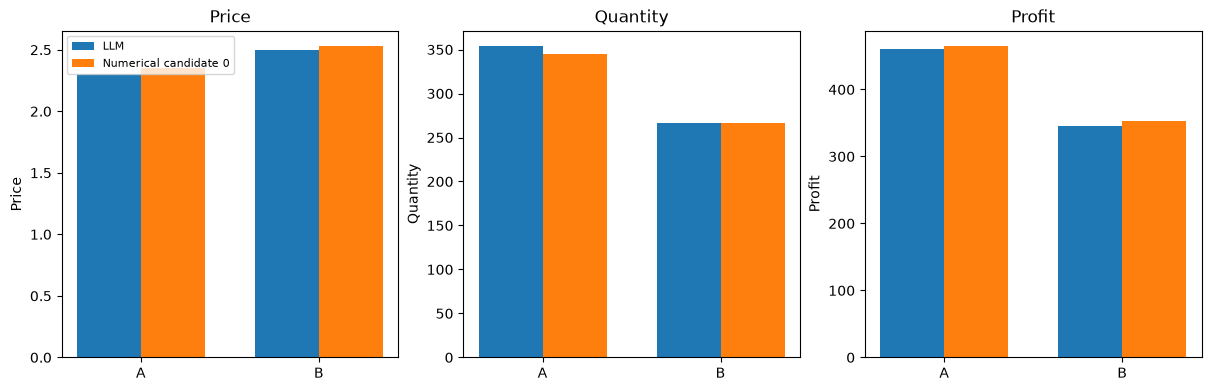

In [5]:
PLOT_REFERENCE_INDEX = 0  # Explicit display choice only; all comparisons remain in the artifact.
if report.result.equilibria:
    equilibrium = report.result.equilibria[PLOT_REFERENCE_INDEX]
    reference_prices = {a.actor_id:a.payload["price"] for a in equilibrium.actions}
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), constrained_layout=True)
    x = np.arange(len(actor_ids))
    panels = [("Price", prices, reference_prices),
              ("Quantity", observed.metrics["quantities"], equilibrium.outcome.metrics["quantities"]),
              ("Profit", observed.payoffs, equilibrium.outcome.payoffs)]
    for ax, (title, actual, reference) in zip(axes, panels):
        ax.bar(x-.18, [actual[aid] for aid in actor_ids], width=.36,
               label="LLM" if USE_LIVE_API else "Fake gateway")
        ax.bar(x+.18, [reference[aid] for aid in actor_ids], width=.36,
               label=f"Numerical candidate {PLOT_REFERENCE_INDEX}")
        ax.set(xticks=x, xticklabels=actor_ids, title=title, ylabel=title)
        ax.axhline(0, color="black", linewidth=.6)
    axes[0].legend(fontsize=8)
    plt.show()


## Consumer segments and the outside option

Each segment's firm shares plus its outside share sum to one. Aggregate firm quantities plus outside demand equal the declared population. The outside option prevents the model from forcing every consumer to buy a product.


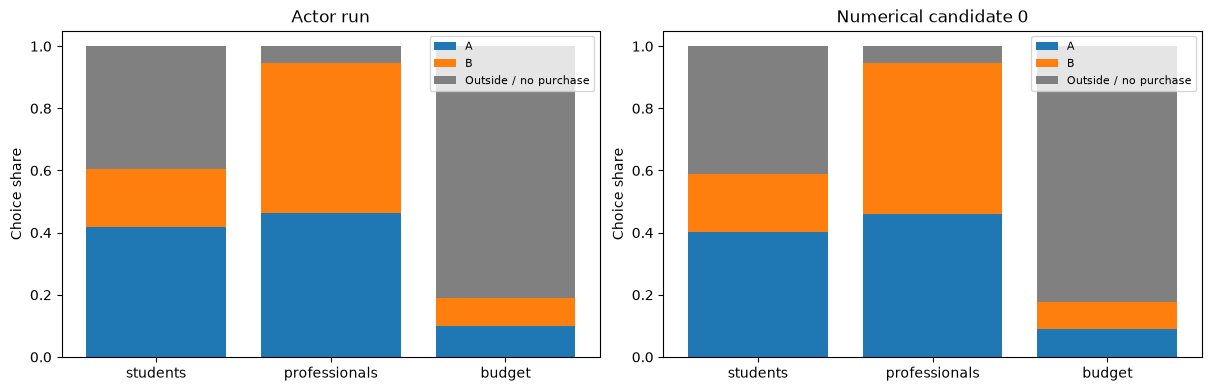

In [6]:
outcomes = [("Actor run", observed)]
if report.result.equilibria:
    outcomes.append((f"Numerical candidate {PLOT_REFERENCE_INDEX}", report.result.equilibria[PLOT_REFERENCE_INDEX].outcome))
fig, axes = plt.subplots(1, len(outcomes), figsize=(6*len(outcomes), 3.8), constrained_layout=True, squeeze=False)
segment_ids = [segment.id for segment in INPUTS.segments]
for ax, (title, outcome) in zip(axes[0], outcomes):
    bottom = np.zeros(len(segment_ids))
    for aid in actor_ids:
        values = [outcome.metrics["segment_shares"][sid][aid] for sid in segment_ids]
        ax.bar(segment_ids, values, bottom=bottom, label=aid)
        bottom += np.array(values)
    outside = [outcome.metrics["outside_shares"][sid] for sid in segment_ids]
    ax.bar(segment_ids, outside, bottom=bottom, label="Outside / no purchase", color="gray")
    ax.set(title=title, ylabel="Choice share", ylim=(0, 1.05))
    ax.legend(fontsize=8)
plt.show()


## Why each firm chose its price

These are the model's stated explanations from the committed decisions. An explanation may contain an assumption about rival pricing; that is not an observation of the rival's hidden current action.


In [7]:
for event in result.events:
    for decision in event.decisions:
        print(f"Turn {event.state.tick} | Firm {decision.action.actor_id} | Price {decision.action.payload['price']:g}")
        print(f"Stated rationale: {decision.rationale}\n")
        assert decision.rationale


Turn 1 | Firm A | Price 2.3
Stated rationale: No history; assumed rival B near cost-plus ~2.5. Computed logit quantities across 3 segments for A prices 2.0-3.0; profit peaks near 2.3 with margin 1.3. Chose 2.3 within [0,10].

Turn 1 | Firm B | Price 2.5
Stated rationale: No history, so assume rival A prices near cost-plus ~2.5. At that rival price, B demand from professionals (high utility 4.2, low sensitivity 0.8) plus students/budget gives highest profit near 2.5 (margin 1.3 x ~289 units) vs lower price loses margin and higher price loses volume. Chose 2.5 within [0,10] to maximize own profit.



## Numerical benchmark confidence and limitations

The solver searches from multiple initial prices using bounded projected-gradient roots, then verifies candidate deviations with uniform/geometric samples, local peak refinement, and independent SHGO optimization. A bounded best-response fallback is available if root search fails. Price bounds, tolerances, failures, and all found solutions are retained.

The `solved` status means a candidate passed these numerical checks; it does not prove uniqueness or rigorous global best responses. Aggregating heterogeneous segments can produce multiple local profit maxima. An upper/lower bound may materially determine the answer; inspect the flags below and reconsider bounds before interpreting an outcome economically.


In [8]:
print("Status:", report.result.status)
print("Scope:", report.result.diagnostics.get("scope", "See failure diagnostics"))
print("Payoff tolerance:", report.result.diagnostics.get("payoff_tolerance"))
print("Price tolerance:", report.result.diagnostics.get("price_tolerance"))
print("Candidates retained:", len(report.result.equilibria))
attempts = report.result.diagnostics.get("attempts", [])
print("Recorded method/verification attempts:", len(attempts))
for attempt in attempts:
    if "checks" in attempt:
        print("Verification:", attempt["method"], "passed:", attempt["verified"])
        for aid, check in attempt["checks"].items():
            print(aid, "gain:", check["gain"], "at lower:", check["at_lower_bound"],
                  "at upper:", check["at_upper_bound"], "independent method:", check["independent"]["method"])
for index, equilibrium in enumerate(report.result.equilibria):
    print("Candidate", index, "verified unilateral gains:", equilibrium.regrets)


Status: solved
Scope: Numerically verified bounded-game candidates; not a proof of global optimality, uniqueness, or completeness
Payoff tolerance: 1e-05
Price tolerance: 1e-05
Candidates retained: 1
Recorded method/verification attempts: 18
Verification: multistart_candidate passed: False
A gain: 644.7814675107322 at lower: False at upper: True independent method: SHGO+uniform-geometric-samples
B gain: 0.0008685817588229838 at lower: False at upper: False independent method: SHGO+uniform-geometric-samples
Verification: multistart_candidate passed: True
A gain: 5.684341886080802e-14 at lower: False at upper: False independent method: SHGO+uniform-geometric-samples
B gain: 1.1368683772161603e-13 at lower: False at upper: False independent method: SHGO+uniform-geometric-samples
Verification: multistart_candidate passed: False
A gain: 0.0019727234690662954 at lower: False at upper: False independent method: SHGO+uniform-geometric-samples
B gain: 486.0838881541946 at lower: False at upper:

## Model-call provenance and canonical replay

Private prompts/responses and memory stay in the internal artifact; only call metadata is displayed here. Replay never calls the model. Temporary manifests have been removed, while the returned artifact retains validated inputs, assumptions, results, and benchmark diagnostics.


In [9]:
rows = ["| Firm | Mode | Model | Attempt | Status | Input tokens | Output tokens |",
        "|---|---|---|---:|---|---:|---:|"]
for call in result.model_calls:
    rows.append(f"| {call.actor_id} | {call.mode} | {call.response_model or call.model} | {call.attempt} | "
                f"{call.status} | {call.input_tokens} | {call.output_tokens} |")
display(Markdown("\n".join(rows)))
assert replay(result.events)[-1] == result.final_state
assert type(artifact).model_validate_json(artifact.model_dump_json()) == artifact
assert abs(observed.metrics["total_quantity"] + observed.metrics["outside_quantity"] - observed.metrics["total_population"]) < 1e-8
print("Replay, serialization, and demand conservation passed.")
print("Config SHA-256:", report.config_sha256)


| Firm | Mode | Model | Attempt | Status | Input tokens | Output tokens |
|---|---|---|---:|---|---:|---:|
| A | live | muse-spark-1.3-contributor | 1 | accepted | 921 | 1070 |
| B | live | muse-spark-1.3-contributor | 1 | accepted | 921 | 797 |

Replay, serialization, and demand conservation passed.
Config SHA-256: 4fe7bf8371ba53cec2c75d8fc963a5efd5d2193f0457a95efbf98906a0fa5b58


## Assumptions and input provenance

No empirical claims follow from illustrative utilities or LLM personas. Utility levels, outside-option normalization, price units, and segment definitions must be justified with user data before treating outcomes as calibrated market predictions.


In [10]:
for assumption in result.assumptions:
    print(f"[{assumption.source}] {assumption.path}: {assumption.rationale}")
print("Mapped user inputs:", [item.name for item in artifact.manifest.request.supplied_inputs])


[default] /world/parameters: Explicit supplied numeric inputs; illustrative inputs are synthetic, not calibrated estimates. Constant marginal costs, no fixed costs, and no capacity constraints.
[model] /world/initial_public_state/demand_model: Segmented logit is the selected structural model, with independent choices within each segment. Utility differences and price sensitivities must use coherent units; the outside option permits no purchase.
[default] /permissions: Complete public market information by default; explicit input permissions override it. Only own permitted private facts/memory are supplied; current rival prices are hidden.
[default] /protocol_parameters/rounds: One simultaneous stage by default; multiple stages do not establish a repeated-game equilibrium.
[default] /benchmark: Compare to bounded numerical candidates, retaining all solutions found and convergence qualifications; neither global optimality nor uniqueness is proved by numerical convergence. The mathematica